# Set 3: EDA + Logistic Regression

**Q1 → Exp 1A / 1B** · **Q2 → Exp 3** (logistic regression)

Datasets: Q1 asks for `Customers.csv`, which we don't have, so this uses **`Stores.csv`** (supermarket customers, with text columns and missing values). Q2 uses `Solar.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Stores.csv")
print(df.shape)
df.head()

(50, 15)


,Branch,City,Customer,Gender,Product line,Unit_price,Quantity,Tax,Total,Payment,cogs,Rating,Age,Quarterly_Tax,Price
0,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,Ewallet,522.83,9.1,23.0,210.0,7469
1,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,Cash,76.40,9.6,23.0,210.0,1528
2,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,Credit card,324.31,7.4,24.0,210.0,4633
3,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,Ewallet,465.76,8.4,26.0,210.0,5822
4,A,Yangon,Normal,Male,Sports and travel,86.31,60,30.2085,634.3785,Ewallet,604.17,5.3,30.0,210.0,8631


### Q1.2 Features with high positive, high negative and no correlation

In [3]:
corr = df.select_dtypes("number").corr()
print(corr.round(2), "\n")
found = {"high positive": [], "high negative": [], "no correlation": []}
for a in corr.columns:
    for b in corr.columns:
        if a < b:                                   # each pair once
            r = corr.loc[a, b]
            if r > 0.5:
                found["high positive"].append(f"{a} & {b} ({r:.2f})")
            elif r < -0.5:
                found["high negative"].append(f"{a} & {b} ({r:.2f})")
            elif abs(r) < 0.2:
                found["no correlation"].append(f"{a} & {b} ({r:.2f})")
for label in ["high positive", "high negative", "no correlation"]:
    print(label.upper(), ":", found[label] if found[label] else "none")

               Unit_price  Quantity   Tax  Total  cogs  Rating   Age  \
Unit_price           1.00      0.05  0.61   0.61  0.61   -0.12  0.20   
Quantity             0.05      1.00  0.23   0.23  0.23   -0.30  0.03   
Tax                  0.61      0.23  1.00   1.00  1.00   -0.10  0.29   
Total                0.61      0.23  1.00   1.00  1.00   -0.10  0.29   
cogs                 0.61      0.23  1.00   1.00  1.00   -0.10  0.31   
Rating              -0.12     -0.30 -0.10  -0.10 -0.10    1.00 -0.16   
Age                  0.20      0.03  0.29   0.29  0.31   -0.16  1.00   
Quarterly_Tax       -0.14      0.03  0.15   0.15  0.15    0.38 -0.25   
Price                1.00      0.05  0.61   0.61  0.61   -0.12  0.20   

               Quarterly_Tax  Price  
Unit_price             -0.14   1.00  
Quantity                0.03   0.05  
Tax                     0.15   0.61  
Total                   0.15   0.61  
cogs                    0.15   0.61  
Rating                  0.38  -0.12  
Age          

Rule used: r > 0.5 = high positive, r < −0.5 = high negative, |r| < 0.2 = no correlation (close to 0).

### Q1.3 Univariate analysis of categorical variables (bar plot)

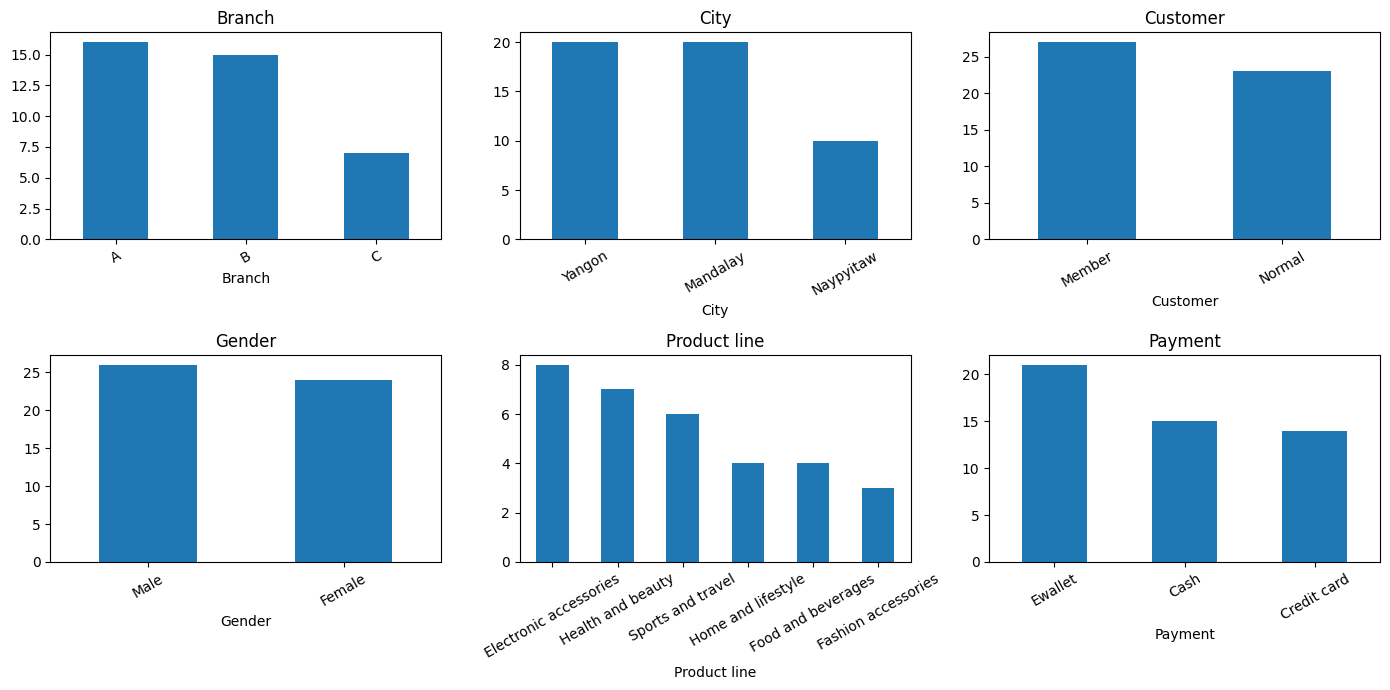

In [4]:
cat_cols = df.select_dtypes("object").columns
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    df[col].value_counts().plot(kind="bar", ax=ax, title=col, rot=30)
plt.tight_layout()
plt.show()

### Q1.4 Display features with missing values > 10% and drop those columns

In [5]:
pct = df.isnull().mean() * 100
print(pct[pct > 0].round(1))
drop_cols = pct[pct > 10].index
print("\nDropping:", list(drop_cols))
df = df.drop(columns=drop_cols)

Branch           24.0
Product line     36.0
cogs              6.0
Rating            4.0
Age               6.0
Quarterly_Tax     4.0
dtype: float64

Dropping: ['Branch', 'Product line']


### Q1.5 Replace missing values with the mean for numerical columns with < 10% missing

In [6]:
pct = df.isnull().mean() * 100                      # % missing in every column
for col in df.select_dtypes("number").columns:
    if 0 < pct[col] < 10:
        df[col] = df[col].fillna(df[col].mean())
        print(f"{col}: {pct[col]:.1f}% missing -> filled with mean")
    else:
        print(f"{col}: {pct[col]:.1f}% missing -> not less than 10%, left as it is")

Unit_price: 0.0% missing -> not less than 10%, left as it is
Quantity: 0.0% missing -> not less than 10%, left as it is
Tax: 0.0% missing -> not less than 10%, left as it is
Total: 0.0% missing -> not less than 10%, left as it is
cogs: 6.0% missing -> filled with mean
Rating: 4.0% missing -> filled with mean
Age: 6.0% missing -> filled with mean
Quarterly_Tax: 4.0% missing -> filled with mean
Price: 0.0% missing -> not less than 10%, left as it is


In [7]:
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


---
## Question 2

### Q2.1 Divide into training (75%) and testing (25%)
`Solar Radiation` is already 0 / 1, so it's the 2 categories.

In [8]:
from sklearn.preprocessing import StandardScaler

solar = pd.read_csv("data/Solar.csv")
X = StandardScaler().fit_transform(solar.drop(columns="Solar Radiation"))
y = solar["Solar Radiation"]
print(y.value_counts().to_dict())

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

{0: 114, 1: 114}
Train: (171, 6)  Test: (57, 6)


### Q2.2 Design the classifier and evaluate on the test set

In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression().fit(X_train, y_train)

### Q2.3 Confusion table and Accuracy, Precision, Recall, F-measure

In [10]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

y_pred = model.predict(X_test)
print("Confusion table:")
print(confusion_matrix(y_test, y_pred))
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, average="macro"), 4))
print("Recall   :", round(recall_score(y_test, y_pred, average="macro"), 4))
print("F-measure:", round(f1_score(y_test, y_pred, average="macro"), 4))

Confusion table:
[[18 10]
 [ 5 24]]
Accuracy : 0.7368
Precision: 0.7442
Recall   : 0.7352
F-measure: 0.7339


### Q2.4 Plot the results

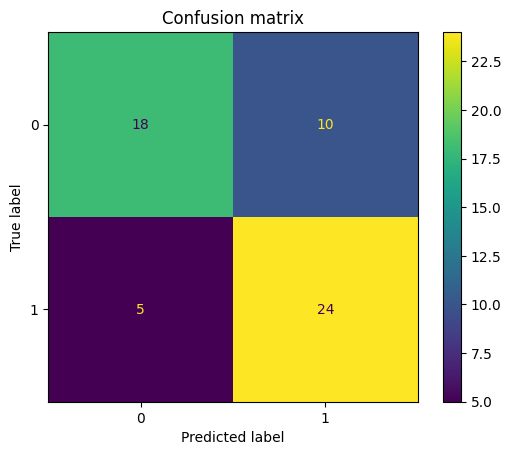

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion matrix")
plt.show()